Este notebook implementa a Parte A do TP1: um equalizador de 3 bandas com filtros FIR projetados com `scipy.signal.firwin`, e a respetiva análise em frequência.

O sinal $x[n]$, amostrado a $F_s = 44100$ Hz, é dividido em três bandas:

| Banda | Filtro | Frequências de corte |
| :--- | :--- | :--- |
| Graves | Passa-baixo | $f_{c1} = 300$ Hz |
| Médios | Passa-banda | $f_{c1} = 300$ Hz, $f_{c2} = 3000$ Hz |
| Agudos | Passa-alto | $f_{c2} = 3000$ Hz |

A saída soma as três bandas, cada uma multiplicada pelo seu ganho:

$$x_{eq}[n] = g_1 \cdot y_{\text{graves}}[n] + g_2 \cdot y_{\text{médios}}[n] + g_3 \cdot y_{\text{agudos}}[n]$$

---
## $0.$ Bibliotecas, Parâmetros e Funções Auxiliares

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, lfilter, freqz
from scipy.io import wavfile

plt.rcParams['figure.figsize'] = (11, 4.5)
plt.rcParams['axes.grid'] = True

In [ ]:
Fs  = 44100  # frequência de amostragem (Hz)
L   = 101    # nº de coeficientes (taps) de cada FIR -> ordem M = L - 1 = 100
fc1 = 300    # fronteira graves / médios (Hz)
fc2 = 3000   # fronteira médios / agudos (Hz)
NPTS = 16384 # nº de pontos do freqz

# Configurações (g1, g2, g3)
BASS_BOOST    = (2.0, 1.0, 0.5)
TREBLE_BOOST  = (0.5, 1.0, 2.0)

AUDIO_DIR = './sounds'
os.makedirs(AUDIO_DIR, exist_ok=True)

In [3]:
def normalize(x, peak=0.99):
    """Normaliza o sinal pelo pico.
    Args:
        x: Sinal.
        peak: Amplitude máxima pretendida (<= 1).
    Returns:
        Sinal escalado com max|x| = peak; inalterado se for nulo.
    """
    m = np.max(np.abs(x))
    return x if m == 0 else peak * x / m

def db(H, floor=1e-12):
    """Converte amplitude para dB.
    Args:
        H: Resposta em frequência ou amplitude.
        floor: Valor somado a |H| para evitar log10(0).
    Returns:
        20 * log10(|H| + floor).
    """
    return 20 * np.log10(np.abs(H) + floor)

def read_wav(path, expected_fs=Fs):
    """Lê um ficheiro .wav.
    Args:
        path: Caminho do ficheiro.
        expected_fs: Frequência de amostragem exigida (Hz).
    Returns:
        Sinal mono em vírgula flutuante, em [-1, 1].
    Raises:
        ValueError: Se a frequência de amostragem for diferente de expected_fs.
    """
    fs, x = wavfile.read(path)
    if fs != expected_fs:
        raise ValueError(f'{path}: Fs = {fs} Hz; converta o ficheiro para {expected_fs} Hz.')
    if np.issubdtype(x.dtype, np.integer):            # int16/int32 -> [-1, 1]
        x = x / float(np.iinfo(x.dtype).max + 1)
    if x.ndim == 2:                                    # estéreo -> mono (média dos canais)
        x = x.mean(axis=1)
    return x.astype(float)

def write_wav(path, x, fs=Fs):
    """Grava um sinal como .wav PCM de 16 bits.
    Args:
        path: Caminho do ficheiro.
        x: Sinal em [-1, 1]; valores fora do intervalo são saturados.
        fs: Frequência de amostragem (Hz).
    """
    wavfile.write(path, fs, (np.clip(x, -1, 1) * (2**15 - 1)).astype(np.int16))

In [4]:
def freq_response_db(h, n=None):
    """Resposta em amplitude de um FIR, em dB.

    Args:
        h: Coeficientes do filtro.
        n: Número de pontos do freqz (por omissão, NPTS).

    Returns:
        (f, H_db): frequências (Hz) e amplitude (dB), sem o ponto f = 0.
    """
    f, H = freqz(h, worN=n or NPTS, fs=Fs)
    return f[1:], db(H[1:])

def format_freq_axis(ax, title, xlim=(20, Fs / 2), ylim=(-90, 5)):
    """Formata um eixo de resposta em frequência (escala log, cortes fc1 e fc2).

    Args:
        ax: Eixo do matplotlib.
        title: Título do gráfico.
        xlim: Limites do eixo das frequências (Hz).
        ylim: Limites do eixo da amplitude (dB).
    """
    ax.set_xscale('log'); ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    for fc in (fc1, fc2):
        ax.axvline(fc, color='gray', ls='--', lw=1)
    ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('Amplitude (dB)')
    ax.set_title(title); ax.grid(True, which='both', alpha=0.4); ax.legend(fontsize=9)

---
## $1.$ Projeto dos filtros FIR

Os três filtros são projetados com `firwin`, com 101 coeficientes (ordem $100$) e janela de Hamming. No passa-banda e no passa-alto usa-se `pass_zero=False`, porque 0 Hz não pertence à banda de passagem.

Mantém-se `scale=True` (valor por omissão), que ajusta cada filtro para ter ganho 1 na sua banda de passagem.

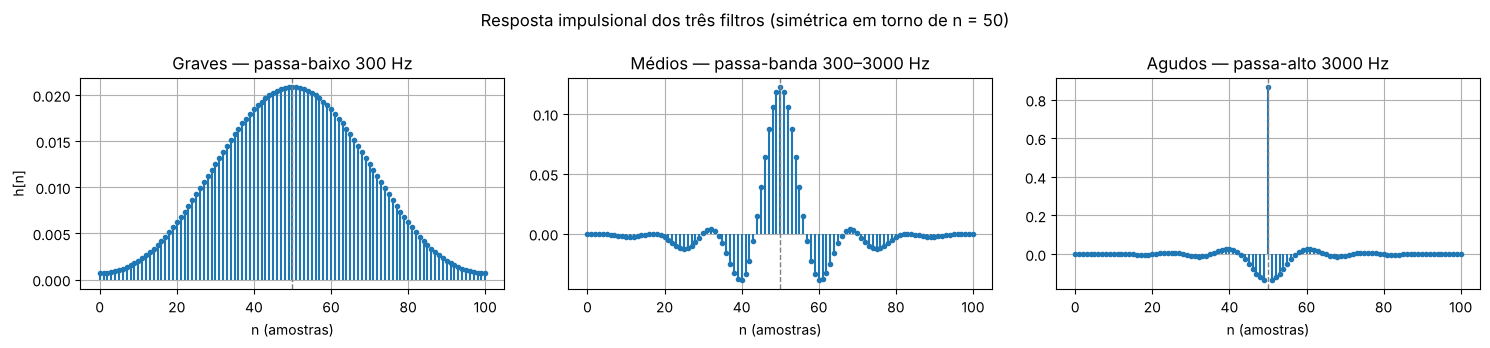

In [5]:
h_low = firwin(L, fc1,        window='hamming', fs=Fs)                   # passa-baixo
h_mid = firwin(L, [fc1, fc2], window='hamming', fs=Fs, pass_zero=False)  # passa-banda
h_high = firwin(L, fc2,       window='hamming', fs=Fs, pass_zero=False)  # passa-alto

FILTERS = [(h_low, f'Graves — passa-baixo {fc1} Hz'),
           (h_mid, f'Médios — passa-banda {fc1}–{fc2} Hz'),
           (h_high, f'Agudos — passa-alto {fc2} Hz')]

fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (h, name) in zip(axs, FILTERS):
    markers = ax.stem(np.arange(L), h, basefmt=' ')[0]
    markers.set_markersize(3)
    ax.axvline((L - 1) / 2, color='gray', ls='--', lw=1)
    ax.set_title(name); ax.set_xlabel('n (amostras)')
axs[0].set_ylabel('h[n]')
fig.suptitle('Resposta impulsional dos três filtros (simétrica em torno de n = 50)')
plt.tight_layout(); plt.show()

**Interpretação**

As três respostas impulsionais são simétricas em torno de $n = 50$, pelo que todas as frequências sofrem o mesmo atraso: 50 amostras (1,13 ms). As três bandas ficam alinhadas e podem ser somadas.

---
## 2. Resposta em frequência $|H(e^{j\omega})|$

A resposta em amplitude de cada filtro é calculada com `freqz` e apresentada em dB, $20\log_{10}|H|$.

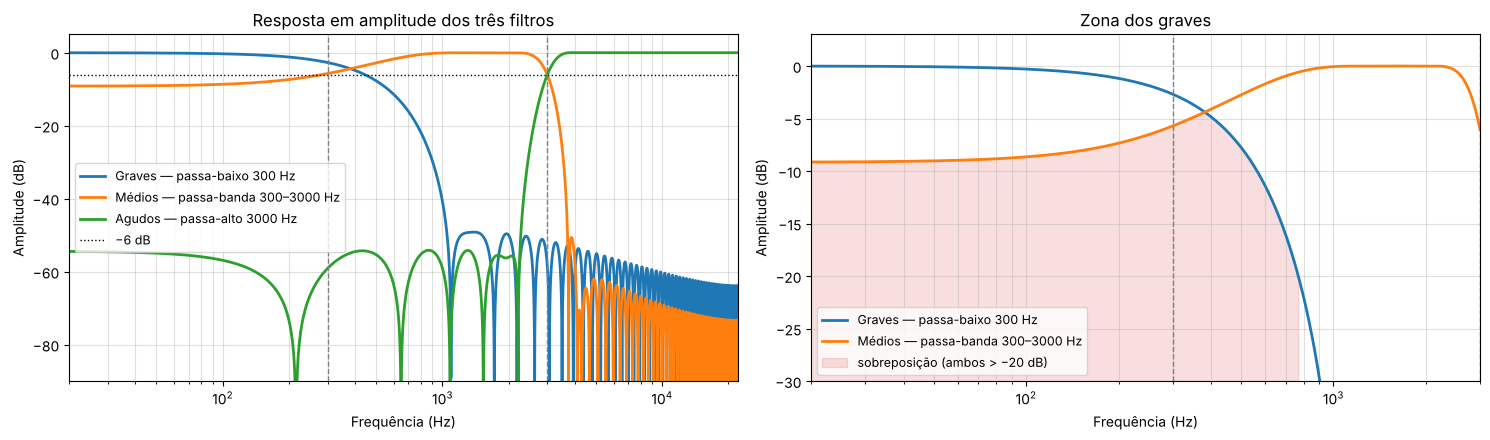

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
for h, name in FILTERS:
    ax1.plot(*freq_response_db(h), lw=2, label=name)
ax1.axhline(-6, color='k', ls=':', lw=1, label='−6 dB')
format_freq_axis(ax1, 'Resposta em amplitude dos três filtros')

f, Hl = freq_response_db(h_low)
_, Hm = freq_response_db(h_mid)
ax2.plot(f, Hl, lw=2, label=FILTERS[0][1])
ax2.plot(f, Hm, lw=2, label=FILTERS[1][1])
ax2.fill_between(f, -30, np.minimum(Hl, Hm), where=np.minimum(Hl, Hm) > -20,
                 color='C3', alpha=0.15, label='sobreposição (ambos > −20 dB)')
format_freq_axis(ax2, 'Zona dos graves', xlim=(20, 3000), ylim=(-30, 3))
plt.tight_layout(); plt.show()

**Interpretação**

Cada filtro tem ganho próximo de 0 dB na sua banda de passagem e atenua as outras em 50 a 60 dB. Em 3000 Hz, o passa-banda e o passa-alto cruzam-se a −6 dB.

O gráfico da direita mostra a zona dos graves. O passa-banda fica a apenas −9 dB em 0 Hz e o passa-baixo só atenua 11 dB a 600 Hz, pelo que os dois filtros se sobrepõem (zona sombreada). A causa é a banda de transição, que, com 101 coeficientes, tem cerca de 1,4 kHz, mais do que toda a banda dos graves.

---
## 3. Implementação do equalizador

Os três filtros estão associados em paralelo, pelo que o equalizador equivale a um único filtro com resposta impulsional

$$h_{eq}[n] = g_1 h_{graves}[n] + g_2 h_{médios}[n] + g_3 h_{agudos}[n].$$

O sinal é filtrado uma só vez com $h_{eq}$, e a resposta em frequência combinada obtém-se com um único `freqz`.

In [7]:
def equalizer_ir(g1, g2, g3):
    """Resposta impulsional do equalizador (associação em paralelo).

    Args:
        g1, g2, g3: Ganhos lineares dos graves, médios e agudos.

    Returns:
        h_eq = g1*h_low + g2*h_mid + g3*h_high.

    Raises:
        ValueError: Se algum ganho for negativo.
    """
    if min(g1, g2, g3) < 0:
        raise ValueError('Os ganhos têm de ser >= 0.')
    return g1 * h_low + g2 * h_mid + g3 * h_high

def equalizer(x, g1, g2, g3):
    """Aplica o equalizador de 3 bandas.

    Args:
        x: Sinal de entrada.
        g1, g2, g3: Ganhos lineares dos graves, médios e agudos.

    Returns:
        x_eq, com o mesmo comprimento que x.
    """
    return lfilter(equalizer_ir(g1, g2, g3), [1.0], x)

---
## 4. Resposta em frequência combinada

| Configuração | $(g_1, g_2, g_3)$ | Ganho ideal (graves / médios / agudos) |
| :--- | :--- | :--- |
| Bass Boost | (2; 1; 0,5) | +6 / 0 / −6 dB |
| Treble Boost | (0,5; 1; 2) | −6 / 0 / +6 dB |

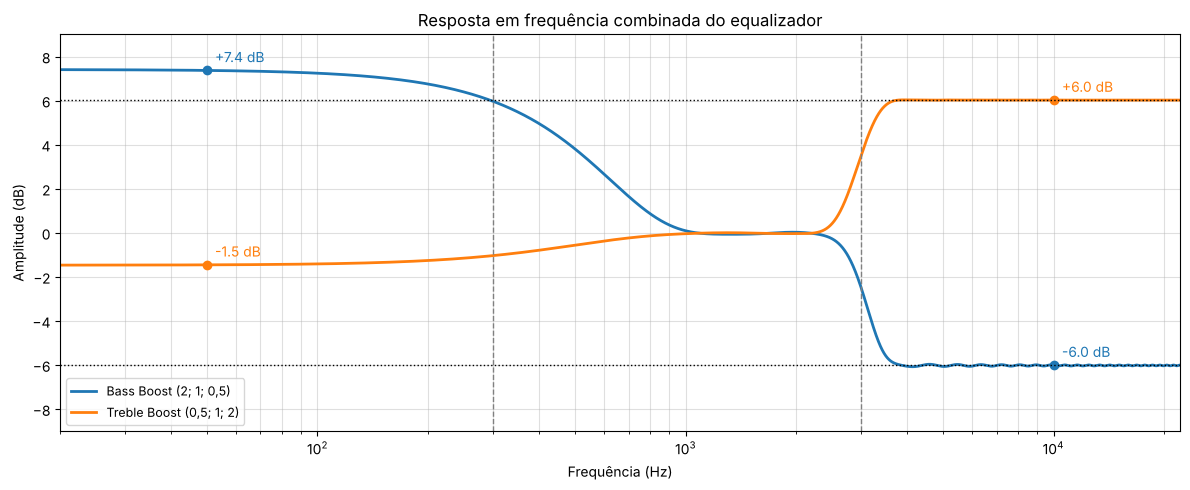

In [8]:
CONFIGS = [(BASS_BOOST,   'Bass Boost (2; 1; 0,5)'),
           (TREBLE_BOOST, 'Treble Boost (0,5; 1; 2)')]

fig, ax = plt.subplots(figsize=(12, 5))
for k, (gains, name) in enumerate(CONFIGS):
    f, H = freq_response_db(equalizer_ir(*gains))
    ax.plot(f, H, lw=2, color=f'C{k}', label=name)
    for f0 in (50, 10000):                       # valores nas bandas extremas
        v = H[np.argmin(np.abs(f - f0))]
        ax.plot(f0, v, 'o', color=f'C{k}')
        ax.annotate(f'{v:+.1f} dB', (f0, v), textcoords='offset points', xytext=(6, 6), color=f'C{k}')
for level in (6.02, -6.02):
    ax.axhline(level, color='k', ls=':', lw=1)
format_freq_axis(ax, 'Resposta em frequência combinada do equalizador', ylim=(-9, 9))
plt.tight_layout(); plt.show()

**Interpretação**

Nos médios e nos agudos o resultado coincide com o ideal: 0 dB nos médios e ±6 dB nos agudos.

Nos graves, como o passa-banda deixa passar 35% do sinal, o ganho é $g_1 + 0{,}35\,g_2$: +7,4 dB no Bass Boost e −1,5 dB no Treble Boost.

---
## 5. Validação com sinusóides

Num SLIT, uma sinusóide sai com a mesma frequência, com a amplitude multiplicada por $|H|$. Aplicam-se tons de amplitude 1 ao equalizador e compara-se a amplitude de saída com $|H|$ obtido pelo `freqz`.

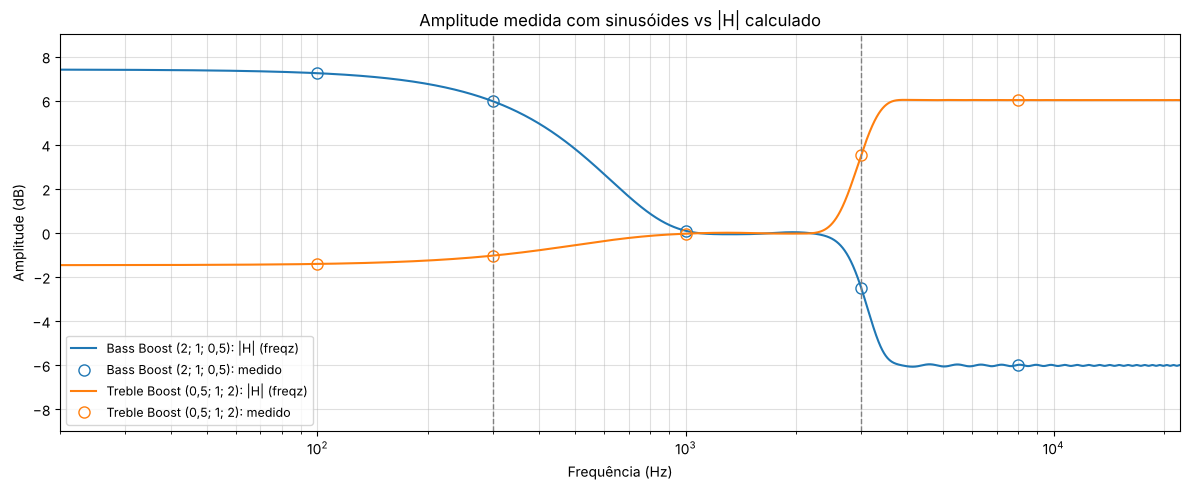

In [9]:
t = np.arange(Fs) / Fs          # 1 segundo
tone_freqs = [100, 300, 1000, 3000, 8000]

fig, ax = plt.subplots(figsize=(12, 5))
for k, (gains, name) in enumerate(CONFIGS):
    A = [np.max(np.abs(equalizer(np.sin(2 * np.pi * f0 * t), *gains)[2 * L:]))   # sem o transitório
         for f0 in tone_freqs]
    ax.plot(*freq_response_db(equalizer_ir(*gains)), lw=1.5, color=f'C{k}', label=f'{name}: |H| (freqz)')
    ax.plot(tone_freqs, db(np.array(A)), 'o', ms=8, mfc='none', color=f'C{k}', label=f'{name}: medido')
format_freq_axis(ax, 'Amplitude medida com sinusóides vs |H| calculado', ylim=(-9, 9))
plt.tight_layout(); plt.show()

**Interpretação**

Os pontos medidos estão sobre as curvas de $|H|$, o que confirma a resposta em frequência calculada com `freqz`.

---
## 6. Prevenção de *clipping*

Com ganhos superiores a 1, a saída pode sair do intervalo $[-1, 1]$ e ser cortada na reprodução. A saída é por isso normalizada pelo seu valor máximo, o que só altera o volume. O exemplo usa ruído branco com o Treble Boost.

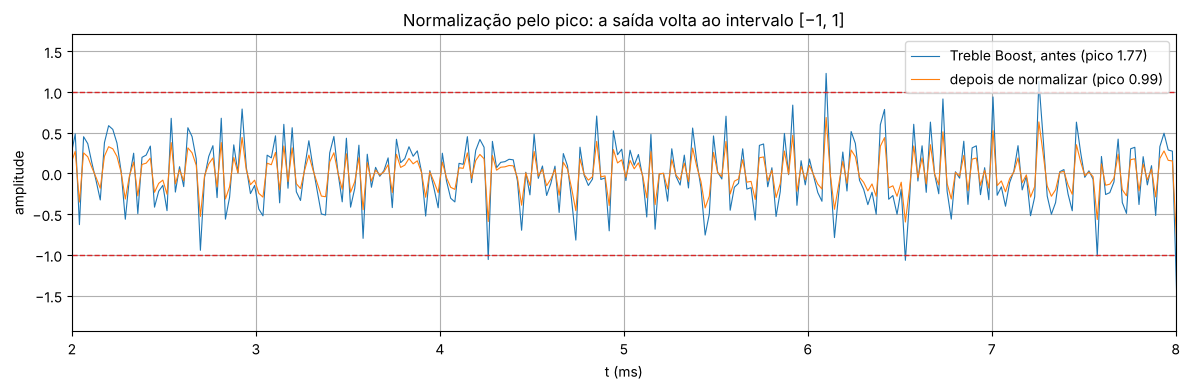

In [10]:
rng = np.random.default_rng(0)
x_demo = 0.9 * normalize(rng.standard_normal(Fs // 2))     # ruído com pico 0,9
y = equalizer(x_demo, *TREBLE_BOOST)
y_n = normalize(y)

t_ms = 1000 * np.arange(len(y)) / Fs
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_ms, y, lw=0.8, label=f'Treble Boost, antes (pico {np.max(np.abs(y)):.2f})')
ax.plot(t_ms, y_n, lw=0.8, label=f'depois de normalizar (pico {np.max(np.abs(y_n)):.2f})')
for level in (1, -1):
    ax.axhline(level, color='C3', ls='--', lw=1)
ax.set_xlim(2, 8); ax.set_xlabel('t (ms)'); ax.set_ylabel('amplitude')
ax.set_title('Normalização pelo pico: a saída volta ao intervalo [−1, 1]')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

---
## 7. Conclusões

Os três filtros FIR têm o mesmo atraso, de 50 amostras, e podem ser somados diretamente.

Com 101 coeficientes, a banda de transição (cerca de 1,4 kHz) é mais larga do que a banda dos graves, e o passa-baixo e o passa-banda sobrepõem-se. Por isso, nos agudos o equalizador dá os ±6 dB esperados, mas nos graves dá +7,4 dB e −1,5 dB.

O teste com sinusóides confirma a resposta em frequência, e a normalização mantém a saída em $[-1, 1]$.